# NSL-KDD: exploratory data analysis

**Purpose.** Profile the NSL-KDD network-connection dataset before we build the
ingest pipeline: size, data quality, class balance, value distributions, and
differences between the training and test files.

| | |
| --- | --- |
| Inputs | `data/raw/nslkdd/KDDTrain+.txt`, `data/raw/nslkdd/KDDTest+.txt` (download with `make eda-data`) |
| Outputs | Figures in `docs/eda/figures/nslkdd_*.png`; numbers in `docs/eda/results/nslkdd_summary.json` |
| Write-up | [`docs/eda/eda-report.md`](../docs/eda/eda-report.md), section 3 |
| Run | `make eda`, or open this notebook with the `eda/.venv` kernel and run all cells |

## 0. Setup

In [1]:
from __future__ import annotations

import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

# Repository root: the first folder, from here upwards, that contains the Makefile.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "Makefile").exists())
FIGURES = ROOT / "docs" / "eda" / "figures"
RESULTS = ROOT / "docs" / "eda" / "results"
FIGURES.mkdir(parents=True, exist_ok=True)
RESULTS.mkdir(parents=True, exist_ok=True)

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 50)


def save(fig: plt.Figure, name: str) -> None:
    """Saves a figure for the EDA report and shows it in the notebook."""
    fig.tight_layout()
    fig.savefig(FIGURES / name, dpi=120)
    plt.show()

RAW = ROOT / "data" / "raw" / "nslkdd"

### Column names and category mapping

The files have no header row. Each row has 41 features, the attack `label`,
and a `difficulty` score. We map each label to one of five categories, and each
category to the severity our system will store (LLD-001 §3.2). The map covers
labels from both files.

In [2]:
FEATURES = [
    "duration", "protocol_type", "service", "flag", "src_bytes", "dst_bytes",
    "land", "wrong_fragment", "urgent", "hot", "num_failed_logins", "logged_in",
    "num_compromised", "root_shell", "su_attempted", "num_root",
    "num_file_creations", "num_shells", "num_access_files", "num_outbound_cmds",
    "is_host_login", "is_guest_login", "count", "srv_count", "serror_rate",
    "srv_serror_rate", "rerror_rate", "srv_rerror_rate", "same_srv_rate",
    "diff_srv_rate", "srv_diff_host_rate", "dst_host_count",
    "dst_host_srv_count", "dst_host_same_srv_rate", "dst_host_diff_srv_rate",
    "dst_host_same_src_port_rate", "dst_host_srv_diff_host_rate",
    "dst_host_serror_rate", "dst_host_srv_serror_rate", "dst_host_rerror_rate",
    "dst_host_srv_rerror_rate",
]
COLUMNS = FEATURES + ["label", "difficulty"]
CATEGORICAL = ["protocol_type", "service", "flag"]
NUMERIC = [c for c in FEATURES if c not in CATEGORICAL]

CATEGORY = {
    "normal": "normal",
    **dict.fromkeys(
        ["back", "land", "neptune", "pod", "smurf", "teardrop", "apache2",
         "mailbomb", "processtable", "udpstorm"], "DoS"),
    **dict.fromkeys(
        ["ipsweep", "nmap", "portsweep", "satan", "mscan", "saint"], "Probe"),
    **dict.fromkeys(
        ["ftp_write", "guess_passwd", "imap", "multihop", "phf", "spy",
         "warezclient", "warezmaster", "named", "sendmail", "snmpgetattack",
         "snmpguess", "xlock", "xsnoop", "worm"], "R2L"),
    **dict.fromkeys(
        ["buffer_overflow", "loadmodule", "perl", "rootkit", "httptunnel",
         "ps", "sqlattack", "xterm"], "U2R"),
}
SEVERITY = {"normal": "INFO", "Probe": "WARN", "DoS": "ERROR", "R2L": "CRITICAL", "U2R": "CRITICAL"}
CATEGORY_ORDER = ["normal", "DoS", "Probe", "R2L", "U2R"]
CATEGORY_COLORS = ["#4caf50", "#e53935", "#fb8c00", "#8e24aa", "#3949ab"]

## 1. Load the data

We also record the length of every line in bytes, to check it against the
64 KB maximum record size in LLD-001.

In [3]:
def load(name: str) -> tuple[pd.DataFrame, pd.Series]:
    path = RAW / name
    df = pd.read_csv(path, header=None, names=COLUMNS)
    line_bytes = pd.Series([len(line.encode()) for line in path.read_text().splitlines()])
    df["category"] = df["label"].map(CATEGORY)
    df["severity"] = df["category"].map(SEVERITY)
    return df, line_bytes


train, train_bytes = load("KDDTrain+.txt")
test, test_bytes = load("KDDTest+.txt")
train.head()

,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,num_failed_logins,logged_in,num_compromised,root_shell,su_attempted,num_root,num_file_creations,num_shells,num_access_files,num_outbound_cmds,is_host_login,is_guest_login,count,srv_count,serror_rate,srv_serror_rate,rerror_rate,srv_rerror_rate,same_srv_rate,diff_srv_rate,srv_diff_host_rate,dst_host_count,dst_host_srv_count,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,label,difficulty,category,severity
0,0,tcp,ftp_data,SF,491,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,2,2,0.0,0.0,0.0,0.0,1.00,0.00,0.00,150,25,0.17,0.03,0.17,0.00,0.00,0.00,0.05,0.00,normal,20,normal,INFO
1,0,udp,other,SF,146,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,13,1,0.0,0.0,0.0,0.0,0.08,0.15,0.00,255,1,0.00,0.60,0.88,0.00,0.00,0.00,0.00,0.00,normal,15,normal,INFO
2,0,tcp,private,S0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,123,6,1.0,1.0,0.0,0.0,0.05,0.07,0.00,255,26,0.10,0.05,0.00,0.00,1.00,1.00,0.00,0.00,neptune,19,DoS,ERROR
3,0,tcp,http,SF,232,8153,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,5,5,0.2,0.2,0.0,0.0,1.00,0.00,0.00,30,255,1.00,0.00,0.03,0.04,0.03,0.01,0.00,0.01,normal,21,normal,INFO
4,0,tcp,http,SF,199,420,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,30,32,0.0,0.0,0.0,0.0,1.00,0.00,0.09,255,255,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,normal,21,normal,INFO


### Profile both files

One function computes every number this notebook reports, so the tables,
charts, and the saved JSON summary always agree.

In [4]:
def profile(df: pd.DataFrame, line_bytes: pd.Series) -> dict:
    raw = df[COLUMNS]
    by_cat = df["category"].value_counts().reindex(CATEGORY_ORDER, fill_value=0)
    return {
        "rows": int(len(raw)),
        "columns": int(raw.shape[1]),
        "missing_values": int(raw.isna().sum().sum()),
        "exact_duplicate_rows": int(raw.duplicated().sum()),
        "duplicate_rows_ignoring_difficulty": int(raw.drop(columns="difficulty").duplicated().sum()),
        "unmapped_labels": sorted(df.loc[df["category"].isna(), "label"].unique().tolist()),
        "distinct_labels": int(raw["label"].nunique()),
        "categories": {k: int(v) for k, v in by_cat.items()},
        "category_share_pct": {k: round(v / len(raw) * 100, 2) for k, v in by_cat.items()},
        "severity": {k: int(v) for k, v in df["severity"].value_counts().items()},
        "protocol_type": {k: int(v) for k, v in raw["protocol_type"].value_counts().items()},
        "flag": {k: int(v) for k, v in raw["flag"].value_counts().items()},
        "distinct_services": int(raw["service"].nunique()),
        "top_services": {k: int(v) for k, v in raw["service"].value_counts().head(10).items()},
        "constant_columns": [c for c in NUMERIC if raw[c].nunique() == 1],
        "difficulty": {int(k): int(v) for k, v in raw["difficulty"].value_counts().sort_index().items()},
        "bytes": {
            col: {
                "zero_share_pct": round((raw[col] == 0).mean() * 100, 1),
                "median": float(raw[col].median()),
                "p99": float(raw[col].quantile(0.99)),
                "max": int(raw[col].max()),
                "skewness": round(float(raw[col].skew()), 1),
            }
            for col in ["duration", "src_bytes", "dst_bytes"]
        },
        "line_bytes": {
            "min": int(line_bytes.min()),
            "median": float(line_bytes.median()),
            "max": int(line_bytes.max()),
        },
    }


train_profile = profile(train, train_bytes)
test_profile = profile(test, test_bytes)

## 2. Shape and data quality

What we check: row and column counts, missing values, duplicate rows, labels
our category map does not cover, columns that never change, and line length.

In [5]:
QUALITY_KEYS = [
    "rows", "columns", "missing_values", "exact_duplicate_rows",
    "duplicate_rows_ignoring_difficulty", "distinct_labels", "unmapped_labels",
    "constant_columns", "line_bytes",
]
pd.DataFrame(
    {"KDDTrain+": {k: train_profile[k] for k in QUALITY_KEYS},
     "KDDTest+": {k: test_profile[k] for k in QUALITY_KEYS}}
)

,KDDTrain+,KDDTest+
rows,125973,22544
columns,43,43
missing_values,0,0
exact_duplicate_rows,0,0
duplicate_rows_ignoring_difficulty,0,0
distinct_labels,23,38
unmapped_labels,[],[]
constant_columns,[num_outbound_cmds],[num_outbound_cmds]
line_bytes,"{'min': 141, 'median': 151.0, 'max': 166}","{'min': 140, 'median': 152.0, 'max': 168}"


## 3. Class balance

How many rows fall into each category, and the severity each category maps to.
The chart uses a log scale because the rarest category is about 1,300 times
smaller than the largest.

In [6]:
balance = pd.DataFrame({
    "train_rows": train_profile["categories"],
    "train_share_pct": train_profile["category_share_pct"],
    "test_rows": test_profile["categories"],
    "test_share_pct": test_profile["category_share_pct"],
}).reindex(CATEGORY_ORDER)
balance["severity"] = balance.index.map(SEVERITY)
balance

,train_rows,train_share_pct,test_rows,test_share_pct,severity
normal,67343,53.46,9711,43.08,INFO
DoS,45927,36.46,7458,33.08,ERROR
Probe,11656,9.25,2421,10.74,WARN
R2L,995,0.79,2754,12.22,CRITICAL
U2R,52,0.04,200,0.89,CRITICAL


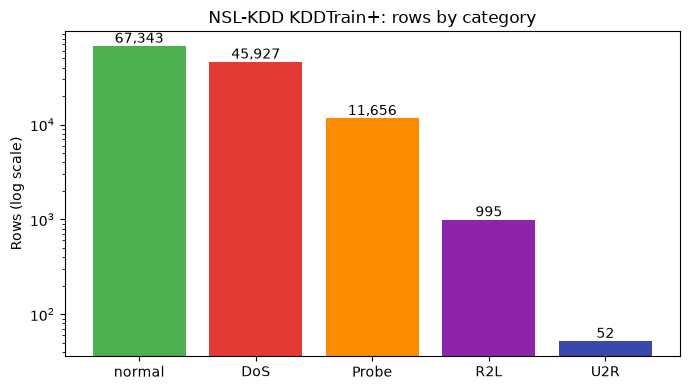

In [7]:
counts = train["category"].value_counts().reindex(CATEGORY_ORDER)
fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(counts.index, counts.values, color=CATEGORY_COLORS)
ax.set_yscale("log")
ax.set_ylabel("Rows (log scale)")
ax.set_title("NSL-KDD KDDTrain+: rows by category")
ax.bar_label(bars, labels=[f"{v:,}" for v in counts.values])
save(fig, "nslkdd_categories.png")

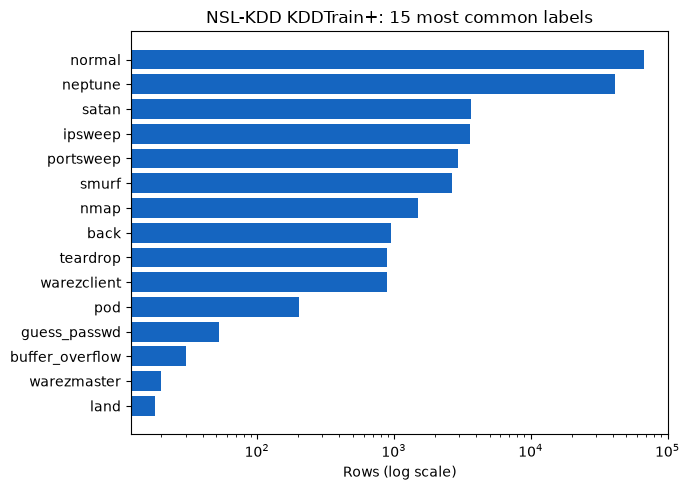

In [8]:
labels = train["label"].value_counts().head(15).sort_values()
fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(labels.index, labels.values, color="#1565c0")
ax.set_xscale("log")
ax.set_xlabel("Rows (log scale)")
ax.set_title("NSL-KDD KDDTrain+: 15 most common labels")
save(fig, "nslkdd_top_labels.png")

## 4. Protocol, connection flag, and service

`flag` describes how a connection ended: `SF` completed normally, `S0` was
never answered (typical of a flood), and `REJ` was refused.

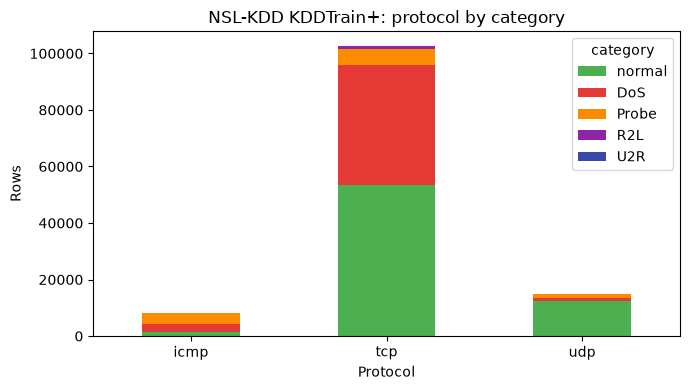

category,normal,DoS,Probe,R2L,U2R
protocol_type,,,,,
icmp,1309,2847,4135,0,0
tcp,53600,42188,5857,995,49
udp,12434,892,1664,0,3


In [9]:
protocol = pd.crosstab(train["protocol_type"], train["category"]).reindex(columns=CATEGORY_ORDER, fill_value=0)
fig, ax = plt.subplots(figsize=(7, 4))
protocol.plot(kind="bar", stacked=True, ax=ax, color=CATEGORY_COLORS)
ax.set_ylabel("Rows")
ax.set_xlabel("Protocol")
ax.set_title("NSL-KDD KDDTrain+: protocol by category")
ax.tick_params(axis="x", rotation=0)
save(fig, "nslkdd_protocol_by_category.png")
protocol

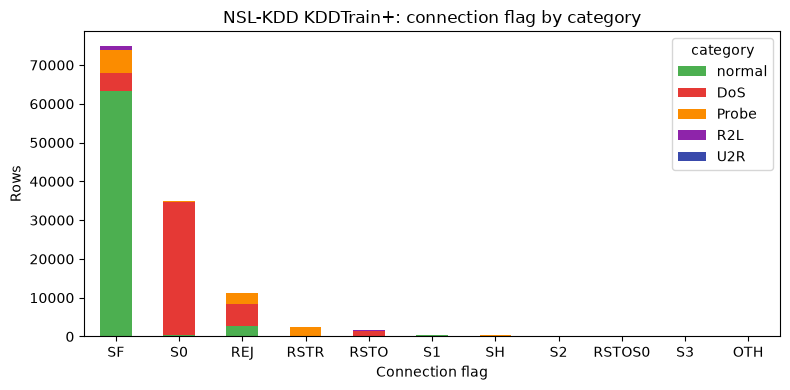

category,normal,DoS,Probe,R2L,U2R
flag,,,,,
SF,63393,4599,5967,935,51
S0,354,34344,153,0,0
REJ,2693,5671,2869,0,0
RSTR,146,90,2180,5,0
RSTO,219,1216,80,46,1
S1,361,2,1,1,0
SH,2,0,265,4,0
S2,119,5,2,1,0
RSTOS0,0,0,103,0,0


In [10]:
flags = pd.crosstab(train["flag"], train["category"]).reindex(columns=CATEGORY_ORDER, fill_value=0)
flags = flags.loc[flags.sum(axis=1).sort_values(ascending=False).index]
fig, ax = plt.subplots(figsize=(8, 4))
flags.plot(kind="bar", stacked=True, ax=ax, color=CATEGORY_COLORS)
ax.set_ylabel("Rows")
ax.set_xlabel("Connection flag")
ax.set_title("NSL-KDD KDDTrain+: connection flag by category")
ax.tick_params(axis="x", rotation=0)
save(fig, "nslkdd_flag_by_category.png")
flags

In [11]:
print(f"Distinct services: train {train_profile['distinct_services']}, test {test_profile['distinct_services']}")
pd.Series(train_profile["top_services"], name="train_rows").to_frame()

Distinct services: train 70, test 64


,train_rows
http,40338
private,21853
domain_u,9043
smtp,7313
ftp_data,6860
eco_i,4586
other,4359
ecr_i,3077
telnet,2353
finger,1767


## 5. Numeric distributions

Byte counts and durations are mostly zero with a few huge values. The
histograms show only non-zero values, on a log scale.

In [12]:
pd.DataFrame(train_profile["bytes"]).T

,zero_share_pct,median,p99,max,skewness
duration,92.0,0.0,9590.56,4.290800e+04,11.9
src_bytes,39.2,44.0,54540.00,1.379964e+09,190.7
dst_bytes,54.0,0.0,25519.00,1.309937e+09,290.1


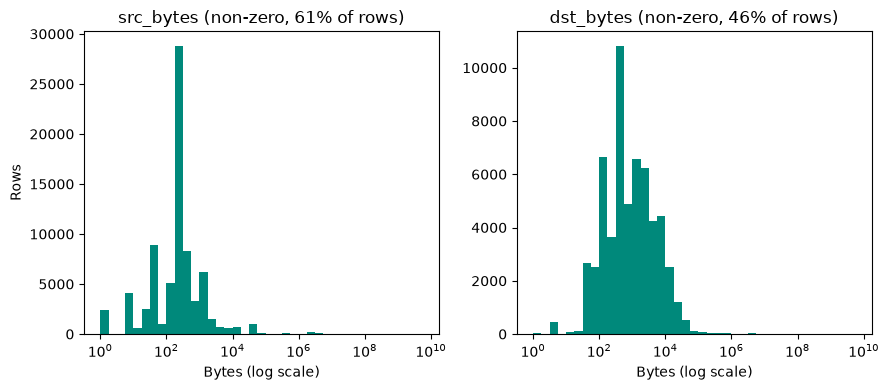

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, col in zip(axes, ["src_bytes", "dst_bytes"]):
    nonzero = train.loc[train[col] > 0, col]
    ax.hist(nonzero, bins=pd.Series([10 ** (i / 4) for i in range(0, 40)]), color="#00897b")
    ax.set_xscale("log")
    ax.set_title(f"{col} (non-zero, {len(nonzero) / len(train):.0%} of rows)")
    ax.set_xlabel("Bytes (log scale)")
axes[0].set_ylabel("Rows")
save(fig, "nslkdd_bytes_distribution.png")

## 6. Training file versus test file

Labels that appear only in the test file, and rows that appear in both files.

In [14]:
test_only_labels = sorted(set(test["label"]) - set(train["label"]))
test_rows_with_test_only_labels = int((~test["label"].isin(set(train["label"]))).sum())

key = [c for c in COLUMNS if c != "difficulty"]
combined = pd.concat([train[key], test[key]], ignore_index=True)
rows_in_both_files = int(
    combined.duplicated().sum() - train[key].duplicated().sum() - test[key].duplicated().sum()
)

difficulty_21_share = train_profile["difficulty"][21] / train_profile["rows"] * 100
print(f"Labels only in the test file ({len(test_only_labels)}): {', '.join(test_only_labels)}")
print(f"Test rows with those labels: {test_rows_with_test_only_labels:,}")
print(f"Rows in both files: {rows_in_both_files:,}")
print(f"Training rows at difficulty 21 (easiest): {difficulty_21_share:.1f} %")

Labels only in the test file (17): apache2, httptunnel, mailbomb, mscan, named, processtable, ps, saint, sendmail, snmpgetattack, snmpguess, sqlattack, udpstorm, worm, xlock, xsnoop, xterm
Test rows with those labels: 3,750
Rows in both files: 610
Training rows at difficulty 21 (easiest): 49.7 %


## 7. Save the summary

The EDA report quotes its numbers from this file.

In [15]:
summary = {
    "train": train_profile,
    "test": test_profile,
    "test_only_labels": test_only_labels,
    "test_rows_with_test_only_labels": test_rows_with_test_only_labels,
    "rows_in_both_files": rows_in_both_files,
}
out = RESULTS / "nslkdd_summary.json"
out.write_text(json.dumps(summary, indent=2) + "\n")
print(f"Wrote {out.relative_to(ROOT)}")

Wrote docs/eda/results/nslkdd_summary.json


## 8. Findings

- **Clean files.** No missing values, no duplicate rows, and every label is
  covered by our category map. Lines are under 170 bytes, far below the 64 KB
  limit.
- **No timestamps or IP addresses.** `loadgen` must add them (DQ-01).
- **Imbalanced classes.** Normal and DoS make up 90 % of the training file;
  U2R is 0.04 %. The test file has far more R2L and U2R, so replaying both
  files gives the dashboards more variety.
- **Floods are visible.** Almost all `S0` (unanswered) connections are DoS
  attacks.
- **Extremely skewed byte counts.** Values exceed 1.3 billion, so `bytes` must
  be a 64-bit integer, and charts need a log scale.
- **One useless column.** `num_outbound_cmds` is always 0.
- **Different labels in the test file.** 17 labels (3,750 rows) appear only in
  the test file; all are mapped.

Design implications are discussed in the [EDA report](../docs/eda/eda-report.md).